# Тема 1. Моделирование геометрической вероятности

### Смоделируйте вычисление геометрической вероятности (на примере из лекции про метание дротиков в игровой круг, площадь которого в два раза меньше площади стены). Показать теоретический расчет и графическую иллюстрацию для рассматриваемого примера.

## На квадратном участке земли со стороной (a=10) м расположена круглая клумба радиуса (r=3) м. Центр клумбы совпадает с центром участка. Считаем, что случайная точка выбирается равномерно по площади участка.

## Найти вероятность того, что выбранная точка окажется внутри клумбы.

Рассмотрим событие $A$ — случайно выбранная точка попала внутрь клумбы.

Поскольку точка равномерно распределена по площади участка, геометрическая вероятность равна отношению площади клумбы к площади всего участка:

$$
P(A)=\frac{S_{\text{клумбы}}}{S_{\text{участка}}}.
$$

Площадь круглой клумбы:

$$
S_{\text{клумбы}}=\pi r^2=9\pi.
$$

Площадь квадратного участка:

$$
S_{\text{участка}}=a^2=100.
$$

Следовательно,

$$
P(A)=\frac{9\pi}{100}\approx 0.2827.
$$

Таким образом, теоретическая вероятность попадания случайной точки в клумбу составляет примерно $28.27\%$.

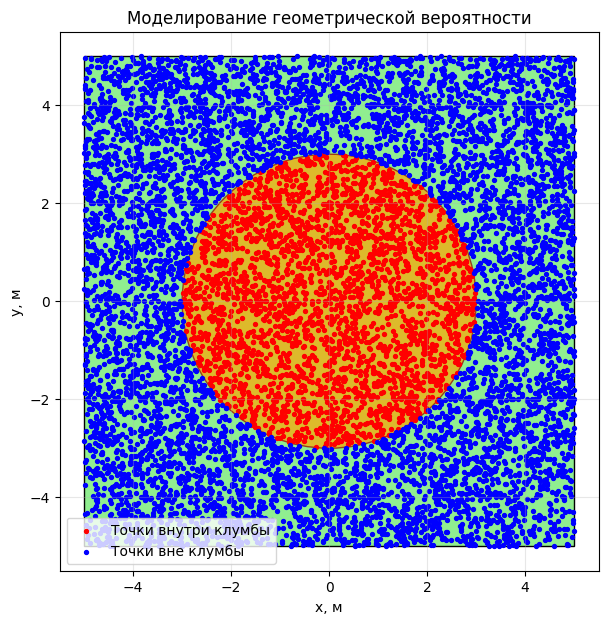

Количество случайных точек: 10000
Точек внутри клумбы: 2813
Экспериментальная вероятность: 0.2813
Теоретическая вероятность: 0.2827


In [12]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle
import numpy as np

def garden(size):
    a = 10
    r = 3

    # Генерация случайных точек на квадратном участке
    rng = np.random.default_rng(42)
    X = rng.uniform(-a / 2, a / 2, size)
    Y = rng.uniform(-a / 2, a / 2, size)

    # Проверка попадания точек в круглую клумбу
    inside = X**2 + Y**2 <= r**2
    count = np.sum(inside)
    prob = count / size

    # Графическая иллюстрация
    fig, ax = plt.subplots(figsize=(7, 7))

    ax.add_patch(Rectangle(
        (-a / 2, -a / 2), a, a,
        facecolor='lightgreen', edgecolor='black'
    ))

    ax.add_patch(Circle(
        (0, 0), r,
        facecolor='orange', edgecolor='darkred',
        alpha=0.7
    ))

    ax.scatter(X[inside], Y[inside], s=8,
               c='red', label='Точки внутри клумбы')
    ax.scatter(X[~inside], Y[~inside], s=8,
               c='blue', label='Точки вне клумбы')

    ax.set_xlim(-a / 2 - 0.5, a / 2 + 0.5)
    ax.set_ylim(-a / 2 - 0.5, a / 2 + 0.5)
    ax.set_aspect('equal')
    ax.set_xlabel('x, м')
    ax.set_ylabel('y, м')
    ax.set_title('Моделирование геометрической вероятности')
    ax.legend()
    ax.grid(True, alpha=0.3)

    plt.show()

    theoretical = np.pi * r**2 / a**2
    print(f'Количество случайных точек: {size}')
    print(f'Точек внутри клумбы: {count}')
    print(f'Экспериментальная вероятность: {prob:.4f}')
    print(f'Теоретическая вероятность: {theoretical:.4f}')

garden(10000)